# TartanIMU: анализ данных

По секунде IMU `(200, 6)` предсказываем среднюю скорость `(vx, vy, vz)` в осях датчика, м/с.
Здесь только данные: состав, различия платформ и проверки перед обучением.

Источник: [описание данных организаторами](https://superodometry.com/imuchallenge/data/).
Все ячейки запускаются по порядку. В IDE выберите Python из `.venv` и выполните все ячейки сверху вниз.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA = ROOT / "data" / "tartan-imu-challenge-iros2026"
assert DATA.is_dir(), "Запустите ноутбук из корня проекта или notebooks/"
sys.path.insert(0, str(ROOT / "notebooks"))
from eda_utils import PLATFORMS, TARGETS, load_indices, audit_trajectories

OUT = ROOT / "reports" / "eda"
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.2})

## Что означают колонки

| Где | Поле | Смысл |
|---|---|---|
| Индекс CSV | `window_id` | Уникальный ID секундного окна |
| Индекс CSV | `traj_id`, `win_idx` | Файл траектории и номер окна; начало = `win_idx × 200` |
| Индекс CSV | `platform` | Домен: car, dog, drone, human; отсутствует в test |
| Targets CSV | `vx`, `vy`, `vz` | Среднее `vel_body` за окно, м/с |
| Индекс CSV | `lb` | Пустое служебное поле; не используем |
| NPZ | `imu: (N,6)` | Ускорение XYZ, м/с², затем гироскоп XYZ, рад/с |
| NPZ | `ts`, `fs` | Время в секундах и частота около 200 Гц |
| NPZ train/val | `vel_body: (N,3)` | Покадровая скорость в осях датчика |
| NPZ train/val | `pos: (N,3)`, `quat: (N,4)` | GT-позиция в метрах и ориентация `[x,y,z,w]` |
| NPZ train/val | `platform_id` | Код платформы: 0 car, 1 dog, 2 drone, 3 human |

**Вход модели — только `imu`.** Остальные поля нужны для сопоставления окон, разбиения и оценки.

## 1. Размеры и готовые split

Окно — одно наблюдение, траектория — группа связанных окон. Функция `load_indices` соединяет CSV по `window_id` и проверяет уникальность ID и непересечение split.

In [2]:
frames = load_indices(DATA)
summary = pd.DataFrame([
    {"split": split, "trajectories": frame.traj_id.nunique(),
     "windows": len(frame), "hours": len(frame) / 3600}
    for split, frame in frames.items()
])
display(summary.round(3))
summary.to_csv(OUT / "split_summary.csv", index=False)

,split,trajectories,windows,hours
0,train,395,81931,22.759
1,val,80,23714,6.587
2,test,89,30644,8.512


## 2. Сколько данных у каждой платформы

Платформы — домены регрессии, а не классы таргета. Число записей и число секунд показываем отдельно: длинные траектории чаще попадают в батчи при обычном перемешивании окон.

,platform,trajectories,windows,split
0,car,44,23533,train
1,dog,36,14915,train
2,drone,289,14213,train
3,human,26,29270,train
4,car,12,7348,val
5,dog,13,6301,val
6,drone,48,2327,val
7,human,7,7738,val


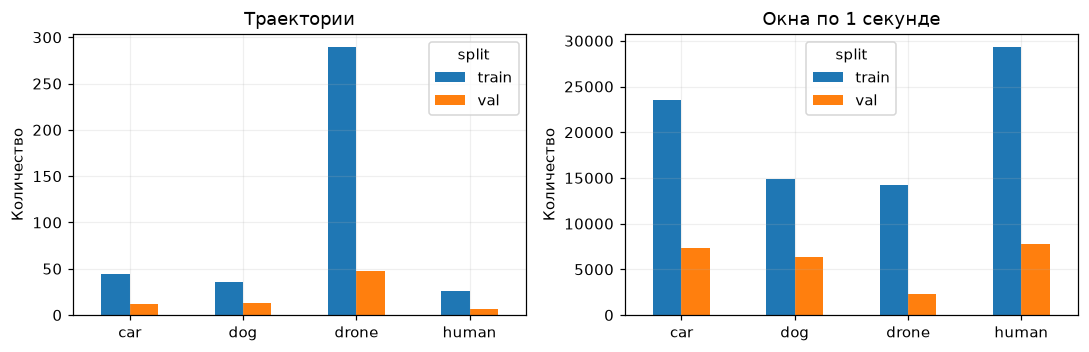

In [3]:
counts = pd.concat([
    frame.groupby("platform").agg(trajectories=("traj_id", "nunique"),
                                  windows=("window_id", "size"))
         .assign(split=split).reset_index()
    for split, frame in frames.items() if split != "test"
], ignore_index=True)
display(counts)
counts.to_csv(OUT / "platform_counts.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
for ax, metric, title in zip(axes, ["trajectories", "windows"], ["Траектории", "Окна по 1 секунде"]):
    table = counts.pivot(index="platform", columns="split", values=metric).reindex(PLATFORMS)
    table.plot.bar(ax=ax, rot=0, title=title)
    ax.set(xlabel="", ylabel="Количество")
fig.tight_layout()
fig.savefig(OUT / "platform_balance.png", bbox_inches="tight")
plt.show()

## 3. Проверки и крупные значения

`audit_trajectories` читает все NPZ: проверяет формы, конечность чисел, порядок времени, полные окна и совпадение таргетов со средним `vel_body`. Код проверок находится в [eda_utils.py](eda_utils.py).

In [4]:
audit = audit_trajectories(DATA, frames)
audit.to_csv(OUT / "trajectory_checks.csv", index=False)
display(audit.groupby("split").agg(
    trajectories=("traj_id", "size"), nonfinite=("nonfinite", "sum"),
    tail_samples=("tail_samples", "sum"), max_target_error=("target_max_abs_error", "max")))

print("Пики train: acc_max — норма ускорения, м/с²; gyro_max — норма угловой скорости, рад/с.")
display(audit[audit.split.eq("train")].nlargest(5, "acc_max")
        [["platform", "traj_id", "acc_max", "gyro_max"]].round(3))

,trajectories,nonfinite,tail_samples,max_target_error
split,,,,
test,89,0,2892,NaN
train,395,0,11933,0.0
val,80,0,2485,0.0


Пики train: acc_max — норма ускорения, м/с²; gyro_max — норма угловой скорости, рад/с.


,platform,traj_id,acc_max,gyro_max
277,drone,drone_train_0197,159.818,17.653
26,car,car_train_0026,125.842,3.113
42,car,car_train_0042,114.706,3.085
285,drone,drone_train_0205,91.055,5.210
31,car,car_train_0031,89.643,2.446


## 4. Распределение целевой скорости

Норма среднего вектора показывает, сколько в каждом домене почти неподвижных и быстрых окон. График — накопленная доля окон с нормой скорости не выше значения на оси X; это не среднее покадровых норм.

,count,50%,90%,99%,max
platform,,,,,
car,23533.0,0.427,1.153,2.225,4.011
dog,14915.0,0.209,0.911,1.377,5.323
drone,14213.0,0.908,3.130,8.060,11.258
human,29270.0,0.112,0.725,1.338,3.952


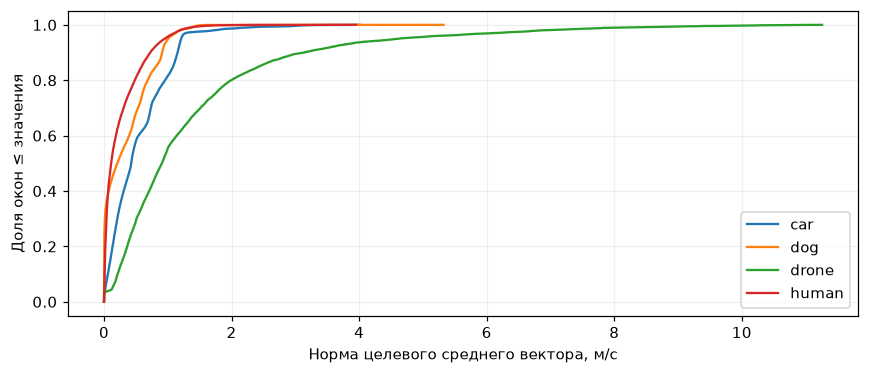

In [5]:
train = frames["train"].copy()
train["speed"] = np.linalg.norm(train[TARGETS].to_numpy(), axis=1)
speed_summary = train.groupby("platform").speed.describe(percentiles=[0.5, 0.9, 0.99]).reindex(PLATFORMS)
display(speed_summary[["count", "50%", "90%", "99%", "max"]].round(3))
speed_summary.to_csv(OUT / "target_speed_train.csv")

fig, ax = plt.subplots(figsize=(8, 3.5))
for domain in PLATFORMS:
    speed = np.sort(train.loc[train.platform.eq(domain), "speed"].to_numpy())
    ax.plot(speed, np.arange(1, len(speed) + 1) / len(speed), label=domain)
ax.set(xlabel="Норма целевого среднего вектора, м/с", ylabel="Доля окон ≤ значения")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "target_speed_train.png", bbox_inches="tight")
plt.show()

## 5. Одинаково ли выглядят оси датчика

Для каждой train-траектории усредним raw-ускорение по времени и сравним компоненты XYZ. Этот сигнал содержит и гравитацию, и движение: различия могут быть связаны с наклоном, установкой датчика и динамикой; график **не доказывает**, куда направлена каждая ось относительно корпуса платформы.

Медиана средних по траекториям: ускорение X/Y/Z, м/с².


,acc_mean_x,acc_mean_y,acc_mean_z
platform,,,
car,0.175,-0.002,9.766
dog,0.045,-0.144,9.637
drone,-0.011,0.033,9.736
human,-1.684,-8.880,1.086


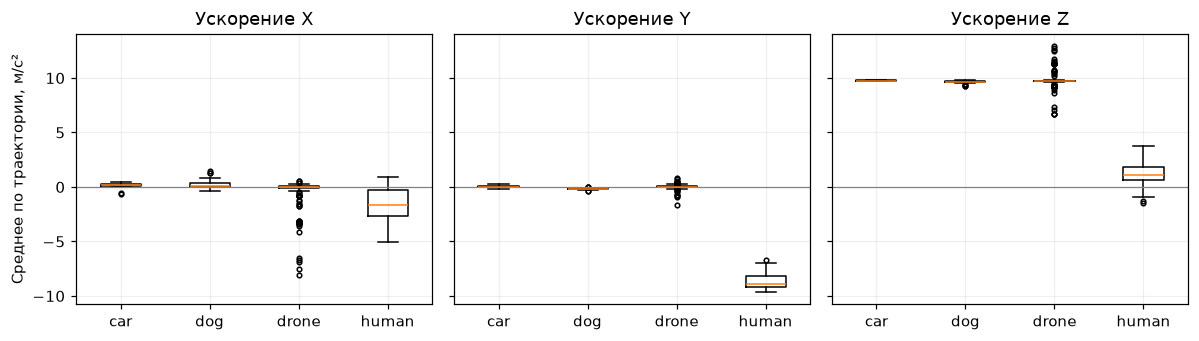

In [6]:
axis_columns = ["acc_mean_x", "acc_mean_y", "acc_mean_z"]
axis_rows = audit[audit.split.eq("train")]
axis_summary = axis_rows.groupby("platform")[axis_columns].median().reindex(PLATFORMS)
print("Медиана средних по траекториям: ускорение X/Y/Z, м/с².")
display(axis_summary.round(3))
axis_summary.to_csv(OUT / "acceleration_axes_train.csv")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for ax, column, label in zip(axes, axis_columns, ["X", "Y", "Z"]):
    groups = [axis_rows.loc[axis_rows.platform.eq(domain), column] for domain in PLATFORMS]
    ax.boxplot(groups, tick_labels=PLATFORMS, flierprops={"markersize": 3})
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set(title=f"Ускорение {label}", xlabel="")
axes[0].set_ylabel("Среднее по траектории, м/с²")
fig.tight_layout()
fig.savefig(OUT / "acceleration_axes_train.png", bbox_inches="tight")
plt.show()

## 6. Примеры движения

XY-проекции GT-пути по одной val-траектории каждого домена. Берём запись с медианным числом окон, не выбирая пример по результатам модели; начало переносим в `(0,0)`. Это иллюстрация данных, а не метрика.

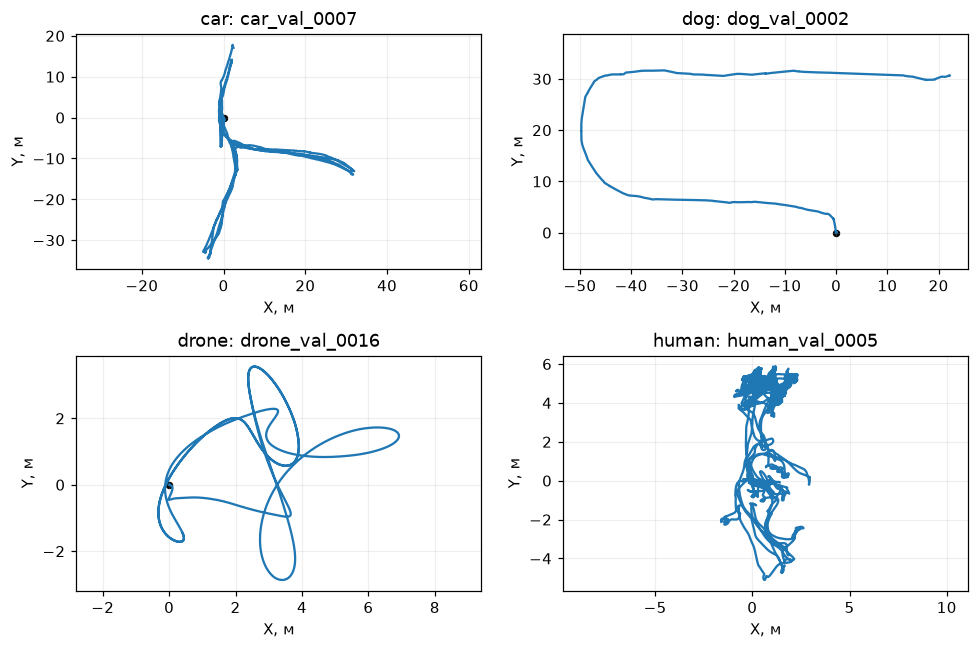

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(9, 6))
selected = []
for ax, domain in zip(axes.flat, PLATFORMS):
    lengths = frames["val"].query("platform == @domain").groupby("traj_id").size().sort_values(kind="stable")
    trajectory = lengths.index[len(lengths) // 2]
    with np.load(DATA / "val" / domain / f"{trajectory}.npz", allow_pickle=False) as archive:
        position = archive["pos"].astype(np.float64)
    xy = position[:, :2] - position[0, :2]
    ax.plot(xy[:, 0], xy[:, 1])
    ax.scatter(0, 0, color="black", s=15)
    ax.set(title=f"{domain}: {trajectory}", xlabel="X, м", ylabel="Y, м")
    ax.set_aspect("equal", adjustable="datalim")
    selected.append({"platform": domain, "traj_id": trajectory, "windows": int(lengths.loc[trajectory])})
fig.tight_layout()
fig.savefig(OUT / "ground_truth_trajectories.png", bbox_inches="tight")
plt.show()
pd.DataFrame(selected).to_csv(OUT / "example_trajectories.csv", index=False)

## Что учитываем при обучении

1. **Разбиваем по целым траекториям.** Стратифицируем траектории по платформе; специалисты используют те же фолды, что и генералист. Общих session/subject ID нет, поэтому пересечение исходных сессий полностью исключить нельзя.
2. **Вход — только IMU.** Позиция, quaternion, платформа и ID не становятся признаками.
3. **Нормализация — только по train-части фолда.** Она меняет масштаб каналов, но не выравнивает ориентацию датчиков.
4. **Учитываем дисбаланс и диапазоны движения.** Смотрим AVE каждой платформы и macro AVE; большое число окон не равно большому числу независимых записей.
5. **Не удаляем гравитацию и пики автоматически.** Неполные хвосты уже исключены индексом. При будущей аугментации вращением нужно согласованно повернуть ускорение, гироскоп и целевой вектор скорости.

Все таблицы и рисунки сохранены в `reports/eda/`.